In [1]:
import sys
from pathlib import Path

print("Python executable:", sys.executable)
print("Python version:", sys.version)

project_root = Path.cwd().parent
data_path = project_root / "data" / "patient_records.csv"

print("Project root:", project_root)
print("Dataset exists:", data_path.exists())

Python executable: /Users/admin/mrna-vip/.venv/bin/python
Python version: 3.12.13 (main, Mar  3 2026, 12:39:30) [Clang 21.0.0 (clang-2100.0.123.102)]
Project root: /Users/admin/mrna-vip
Dataset exists: True


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the dataset
df = pd.read_csv("../data/patient_records.csv")

# Basic inspection
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nStatistical summary:")
display(df.describe().round(2))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Count"))

Dataset shape: (500, 7)

Column names:
['Patient_ID', 'Age', 'Biomarker_Level', 'Pre_Existing_Conditions', 'Vaccine_Dose_mcg', 'Prior_Reaction_History', 'Reaction_Score']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Patient_ID               500 non-null    str    
 1   Age                      500 non-null    int64  
 2   Biomarker_Level          480 non-null    float64
 3   Pre_Existing_Conditions  500 non-null    int64  
 4   Vaccine_Dose_mcg         500 non-null    float64
 5   Prior_Reaction_History   192 non-null    str    
 6   Reaction_Score           500 non-null    int64  
dtypes: float64(2), int64(3), str(2)
memory usage: 27.5 KB

Statistical summary:


,Age,Biomarker_Level,Pre_Existing_Conditions,Vaccine_Dose_mcg,Reaction_Score
count,500.00,480.00,500.00,500.00,500.00
mean,51.44,5.28,1.26,86.55,0.49
std,19.44,2.84,1.20,36.23,0.50
min,18.00,0.64,0.00,25.10,0.00
25%,35.00,3.18,0.00,56.78,0.00
50%,51.00,4.82,1.00,84.55,0.00
75%,68.25,6.95,2.00,118.68,1.00
max,85.00,15.76,4.00,150.00,1.00



Missing values:


,Missing Count
Patient_ID,0
Age,0
Biomarker_Level,20
Pre_Existing_Conditions,0
Vaccine_Dose_mcg,0
Prior_Reaction_History,308
Reaction_Score,0


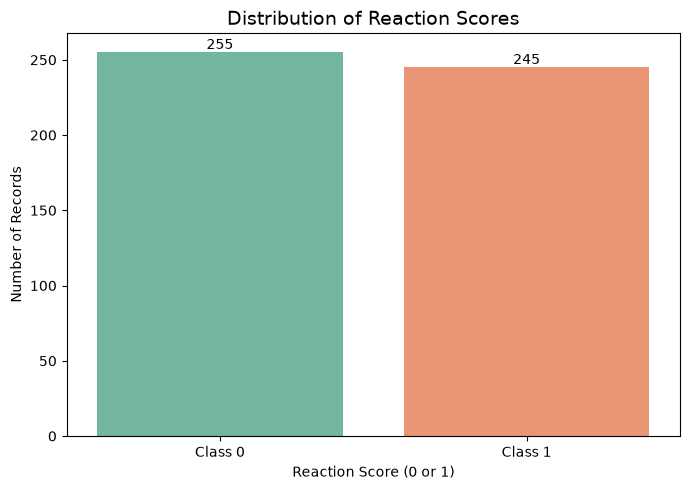

Class proportions (%):


Reaction_Score
0    51.0
1    49.0
Name: Percentage, dtype: float64

In [3]:

# Visualization 1: Distribution of the target variable

target_counts = df["Reaction_Score"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
ax = sns.countplot(
    data=df,
    x="Reaction_Score",
    hue="Reaction_Score",
    palette="Set2",
    legend=False,
)

plt.title("Distribution of Reaction Scores", fontsize=14)
plt.xlabel("Reaction Score (0 or 1)")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ["Class 0", "Class 1"])

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.savefig(
    "../outputs/figures/reaction_score_distribution.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Class proportions (%):")
display((target_counts / len(df) * 100).round(2).rename("Percentage"))


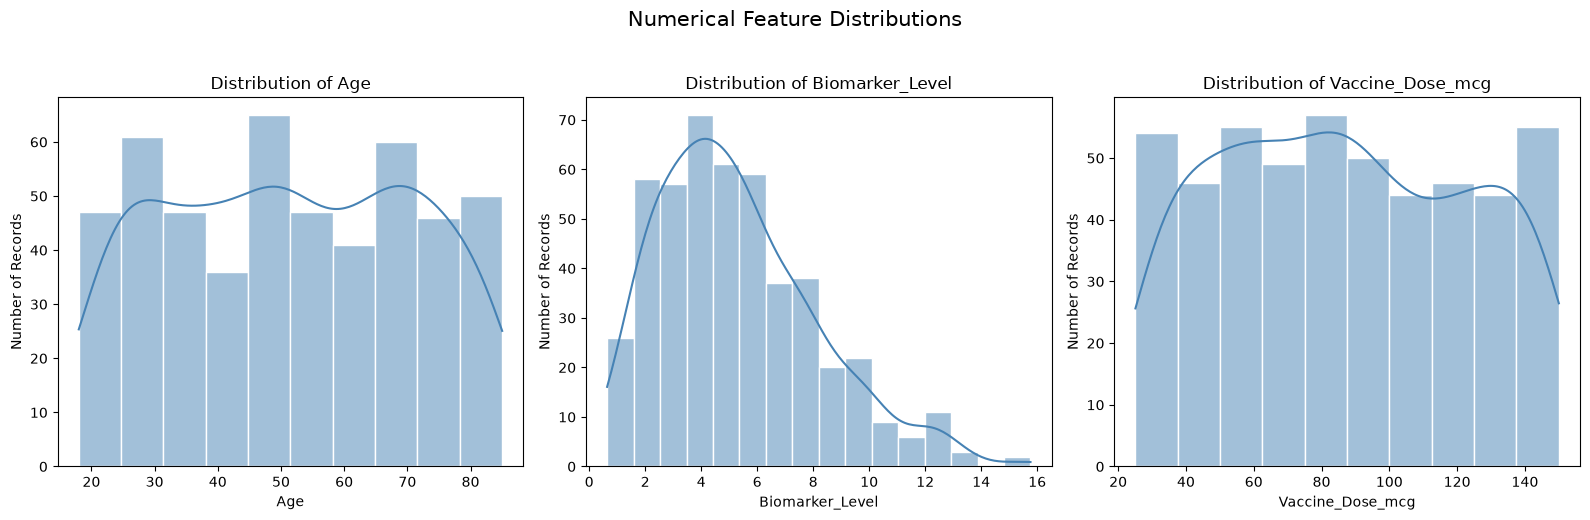

Missing biomarker values: 20


In [4]:

# Visualization 2: Distributions of numerical features

numeric_features = ["Age", "Biomarker_Level", "Vaccine_Dose_mcg"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, numeric_features):
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=ax,
        color="steelblue",
        edgecolor="white",
    )
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Records")

plt.suptitle("Numerical Feature Distributions", fontsize=15, y=1.03)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/numerical_feature_distributions.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Missing biomarker values:", df["Biomarker_Level"].isna().sum())


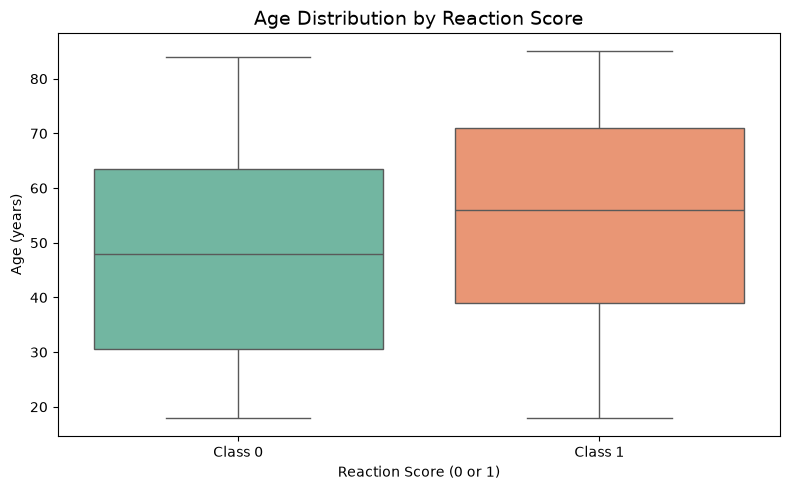

Median age by reaction score:


Reaction_Score
0    48.0
1    56.0
Name: Median Age, dtype: float64

In [5]:

# Visualization 3: Age distribution by reaction score

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Reaction_Score",
    y="Age",
    hue="Reaction_Score",
    palette="Set2",
    legend=False,
)

plt.title("Age Distribution by Reaction Score", fontsize=14)
plt.xlabel("Reaction Score (0 or 1)")
plt.ylabel("Age (years)")
plt.xticks([0, 1], ["Class 0", "Class 1"])
plt.tight_layout()

plt.savefig(
    "../outputs/figures/age_by_reaction_score.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Median age by reaction score:")
display(df.groupby("Reaction_Score")["Age"].median().rename("Median Age"))



## Exploratory Data Analysis — Findings

### 1. Dataset overview
The dataset contains 500 records and 7 columns. The target variable is `Reaction_Score`, with two observed classes: 0 and 1.

### 2. Target distribution
Class 0 contains 255 records (51%), while Class 1 contains 245 records (49%). The target classes are nearly balanced, so neither class strongly dominates the dataset.

### 3. Numerical feature distributions
The recorded ages range from 18 to 85 years. `Biomarker_Level` is right-skewed among its observed values, with a longer tail toward higher values. `Vaccine_Dose_mcg` spans approximately 25 to 150 mcg in this dataset.

### 4. Missing values
There are 20 missing values in `Biomarker_Level` and 308 missing values in `Prior_Reaction_History`. These missing values should be handled by preprocessing steps fitted only on the training set to prevent data leakage. The raw dataset is preserved unchanged.

### 5. Age and reaction-score comparison
The median age is 48 years for Class 0 and 56 years for Class 1. The box plots overlap substantially. This descriptive difference does not establish causation or prove that age alone predicts the target.

### 6. Limitations
This is a small educational dataset. The visualizations describe the supplied records and do not establish real-world vaccine safety relationships. The classifier results are preliminary and must not be used for clinical decisions.
